In [1]:
%pip install pandas openpyxl numpy matplotlib seaborn scikit-learn


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_curve,
    roc_auc_score
)

# Load the dataset
df = pd.read_excel("breast_cancer_wisconsin_diagnostic.xlsx")

# Display the first five rows
df.head()

,ID,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,2,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,3,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,4,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,5,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


In [4]:
print("Dataset column names:")
print(df.columns.tolist())

Dataset column names:
['ID', 'mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'Diagnosis']


In [5]:
print("Missing values in the dataset:")
print(df.isnull().sum().sum())

Missing values in the dataset:
0


In [6]:
print(df["Diagnosis"].value_counts())

Diagnosis
benign       357
malignant    212
Name: count, dtype: int64


In [7]:
# Input features: exclude ID and Diagnosis
X = df.drop(columns=["ID", "Diagnosis"])

# Target variable
y = df["Diagnosis"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput feature names:")
print(X.columns.tolist())

print("\nTarget categories:")
print(y.unique())

Input features shape: (569, 30)
Target shape: (569,)

Input feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target categories:
<ArrowStringArray>
['malignant', 'benign']
Length: 2, dtype: str


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining diagnosis distribution:")
print(y_train.value_counts())

print("\nTesting diagnosis distribution:")
print(y_test.value_counts())

Training features: (455, 30)
Testing features: (114, 30)
Training target: (455,)
Testing target: (114,)

Training diagnosis distribution:
Diagnosis
benign       285
malignant    170
Name: count, dtype: int64

Testing diagnosis distribution:
Diagnosis
benign       72
malignant    42
Name: count, dtype: int64


In [9]:
Training features: (455, 30)
Testing features: (114, 30)
Training target: (455,)
Testing target: (114,)

Training diagnosis distribution:
Diagnosis
benign       286
malignant    169

Testing diagnosis distribution:
Diagnosis
benign       71
malignant    43

SyntaxError: invalid syntax (497101290.py, line 1)

In [10]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [11]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Diagnosis": y_test,
    "Predicted Diagnosis": y_pred
})

display(results.head(10))

,Actual Diagnosis,Predicted Diagnosis
120,benign,benign
250,malignant,malignant
375,benign,benign
99,malignant,malignant
455,benign,benign
318,benign,benign
39,malignant,malignant
371,benign,benign
98,benign,benign
502,benign,benign


In [12]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 97.37 %


Confusion Matrix:
[[72  0]
 [ 3 39]]


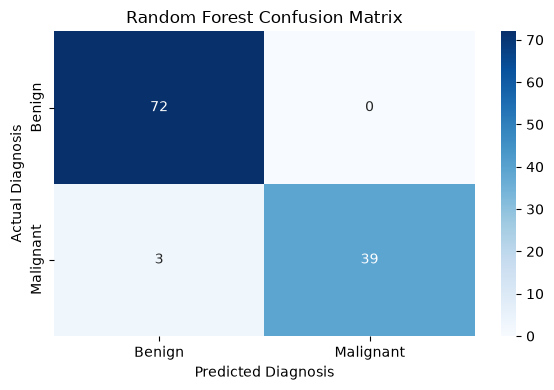

In [13]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["benign", "malignant"]
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

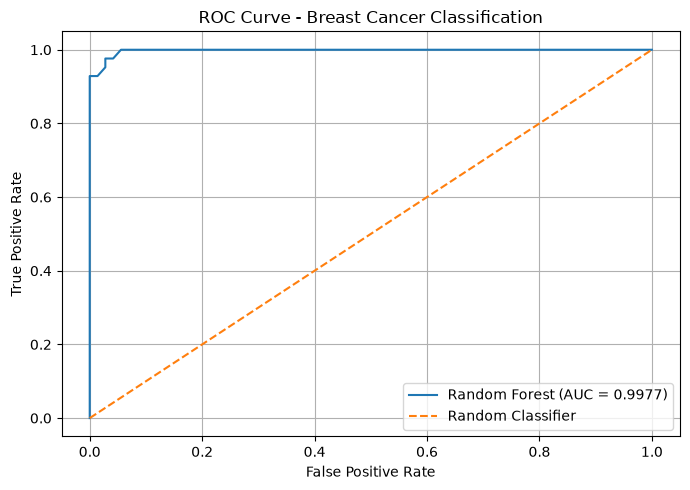

AUC Score: 0.9977


In [14]:
y_prob = model.predict_proba(X_test)

malignant_index = list(model.classes_).index("malignant")

malignant_prob = y_prob[:, malignant_index]

y_test_binary = (y_test == "malignant").astype(int)

fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    malignant_prob
)

auc_score = roc_auc_score(
    y_test_binary,
    malignant_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {auc_score:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Breast Cancer Classification")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

print("AUC Score:", round(auc_score, 4))

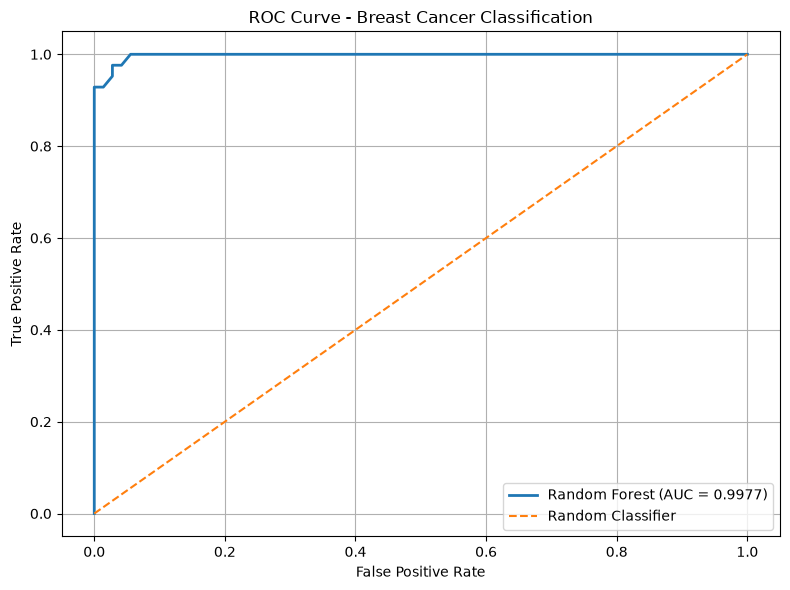

ROC curve saved successfully as roc_curve.png


In [15]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {auc_score:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Breast Cancer Classification")
plt.legend(loc="lower right")
plt.grid(True)

plt.tight_layout()

plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")

plt.show()

print("ROC curve saved successfully as roc_curve.png")

In [16]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

Classification Report:
              precision    recall  f1-score   support

      benign     0.9600    1.0000    0.9796        72
   malignant     1.0000    0.9286    0.9630        42

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



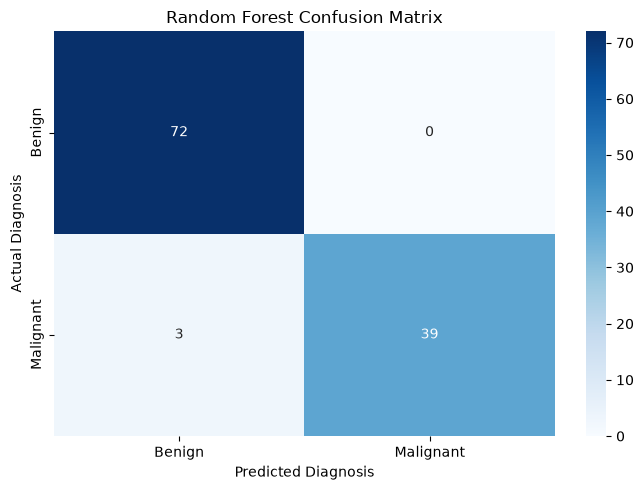

Confusion matrix saved successfully as confusion_matrix.png


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["benign", "malignant"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved successfully as confusion_matrix.png")

In [19]:
import joblib

joblib.dump(model, "random_forest_model.pkl")

print("Model saved successfully as random_forest_model.pkl")

Model saved successfully as random_forest_model.pkl


In [20]:
import pandas as pd

results = pd.DataFrame({
    "Actual Diagnosis": y_test,
    "Predicted Diagnosis": y_pred
})

results["Prediction Status"] = (
    results["Actual Diagnosis"] == results["Predicted Diagnosis"]
).map({True: "Correct", False: "Incorrect"})

results.to_csv("prediction_results.csv", index=False)

print("Prediction results saved successfully!")
display(results.head(10))

Prediction results saved successfully!


,Actual Diagnosis,Predicted Diagnosis,Prediction Status
120,benign,benign,Correct
250,malignant,malignant,Correct
375,benign,benign,Correct
99,malignant,malignant,Correct
455,benign,benign,Correct
318,benign,benign,Correct
39,malignant,malignant,Correct
371,benign,benign,Correct
98,benign,benign,Correct
502,benign,benign,Correct
